In [1]:
import alphashape
import numpy as np
import regionmask
import xarray as xr

mesh_nc = xr.open_dataset("inputs/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.nc")
alpha_shape = alphashape.alphashape(
    np.column_stack([mesh_nc.mesh2d_node_x.values, mesh_nc.mesh2d_node_y.values])[
        ::5, :
    ],
    10,
)
my_region = regionmask.Regions([alpha_shape], name="my_region")
my_region

<regionmask.Regions 'my_region'>
overlap:  None

Regions:
0 r0 Region0

[1 regions]

In [3]:
from utils.simulations import generate_cases

goals_config = {
    1: {"lon": 7.0, "lat": 54.0, "angles": [-70, 180]},
    2: {"lon": 6.5, "lat": 54.0, "angles": [0, 180]},
    3: {"lon": 6.0, "lat": 54.0, "angles": [0, 180]},
    4: {"lon": 5.5, "lat": 54.0, "angles": [0, 180]},
    5: {"lon": 5.0, "lat": 54.0, "angles": [0, 225]},
    6: {"lon": 4.5, "lat": 53.5, "angles": [45, 225]},
    7: {"lon": 4.0, "lat": 53.0, "angles": [45, 225]},
    8: {"lon": 3.5, "lat": 52.5, "angles": [45, 225]},
    9: {"lon": 3.0, "lat": 52.0, "angles": [45, 225]},
    10: {"lon": 2.5, "lat": 51.5, "angles": [45, 310]},
}
cases_df, lhs = generate_cases(goals_config, num_samples_per_goal=2000)
cases_df

,goal,tp,wd,ds,zs
0,1,11.062417,353.368808,28.320828,1.855180
1,1,1.347817,123.052916,1.245791,2.599068
2,1,14.128153,33.003445,34.973423,1.513616
3,1,3.566692,46.598554,20.507330,-1.300087
4,1,8.552062,55.425389,33.203524,-0.889918
...,...,...,...,...,...
19995,10,13.514636,44.626615,24.391003,-2.959140
19996,10,1.292034,247.778591,7.914117,-0.233449
19997,10,12.531377,304.546880,18.870942,-0.430107
19998,10,12.769201,313.712117,28.929450,-0.912727


(<Figure size 640x480 with 6 Axes>,
 array([[<Axes: xlabel='wd', ylabel='tp'>, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: xlabel='ds', ylabel='wd'>, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: xlabel='zs', ylabel='ds'>]],
       dtype=object))

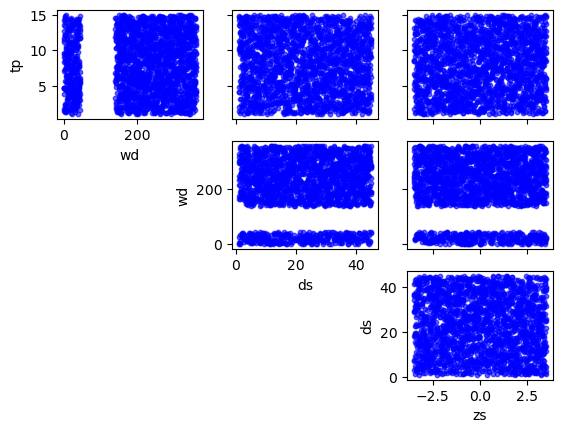

In [4]:
lhs.plot_generated_data()

<Axes: xlabel='tp', ylabel='zs'>

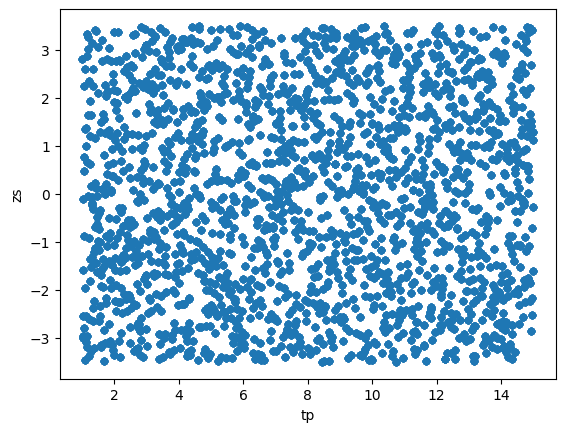

In [3]:
cases_df.plot.scatter(x="tp", y="zs")

In [4]:
from bluemath_tk.wrappers.snapwave.snapwave_wrapper import SnapWaveModelWrapper

snapwave_wrapper = SnapWaveModelWrapper(
    templates_dir="templates-metamodel",
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={},
    output_dir="SnapWave_CASES_METAMODEL",
    region_of_interest=my_region,
    goals_config=goals_config,
)
snapwave_wrapper

2026-04-22 08:04:02,389 - SnapWaveModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-04-22 08:04:02,390 - SnapWaveModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-04-22 08:04:02,390 - SnapWaveModelWrapper - WARNING - Parameter wd is not in the default_parameters
2026-04-22 08:04:02,390 - SnapWaveModelWrapper - WARNING - Parameter ds is not in the default_parameters
2026-04-22 08:04:02,391 - SnapWaveModelWrapper - WARNING - Parameter zs is not in the default_parameters


In [5]:
snapwave_wrapper.calculate_output_grid_parameters(output_grid_resolution=0.01)

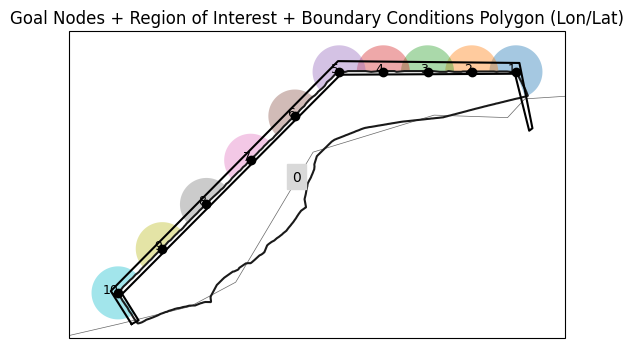

In [6]:
snapwave_wrapper.plot_configuration()

In [7]:
snapwave_wrapper.load_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [8]:
# snapwave_wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [10]:
snapwave_wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    20000
Name: count, dtype: int64

In [11]:
result_msg = snapwave_wrapper.postprocess_cases()
result_msg

'Olrait!'